In [ ]:
!pip -q install sentence-transformers scikit-learn pandas numpy matplotlib


In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.cluster import Birch
from sklearn.feature_extraction.text import TfidfVectorizer


In [ ]:
from google.colab import files
uploaded = files.upload()

JSON_FILE = list(uploaded.keys())[0]
print("Using file:", JSON_FILE)


Saving reduced_icecat_data_train_transformed.json to reduced_icecat_data_train_transformed.json
Using file: reduced_icecat_data_train_transformed.json


In [ ]:
df["ml_text"] = (
    df["BrandInfo.BrandName"].fillna("") + " " +
    df["BrandPartCode"].fillna("") + " " +
    df["SummaryDescription"].fillna("")
).str.strip()

df_ml = df[df["ml_text"].str.len() >= 20].copy()
print("Rows used for ML:", len(df_ml))
df_ml[["ID","ml_text","cat_3lvl"]].head(5)


Rows used for ML: 8665


KeyError: "['cat_3lvl'] not in index"

Step 5 — Keep only the columns we need (clean + faster)

In [ ]:
df["ml_text"] = (
    df["BrandInfo.BrandName"].fillna("") + " " +
    df["BrandPartCode"].fillna("") + " " +
    df["SummaryDescription"].fillna("")
).str.strip()

df_ml = df[df["ml_text"].str.len() >= 20].copy()
print("Rows used for ML:", len(df_ml))
df_ml[["ID","ml_text","cat_3lvl"]].head(5)


Rows used for ML: 8665


KeyError: "['cat_3lvl'] not in index"

Step 6 — Convert category path into list + measure depth

In [ ]:
def split_cat_path(x):
    if pd.isna(x) or x is None:
        return []
    return [p.strip() for p in str(x).split(">") if p.strip()]

df["cat_list"] = df["pathlist_names"].apply(split_cat_path)
df["depth"] = df["cat_list"].apply(len)

depth_counts = df["depth"].value_counts().sort_index()
depth_counts


,count
depth,
3,18741
4,13025


Step 7 — Visualize depth distribution (shows inconsistency)

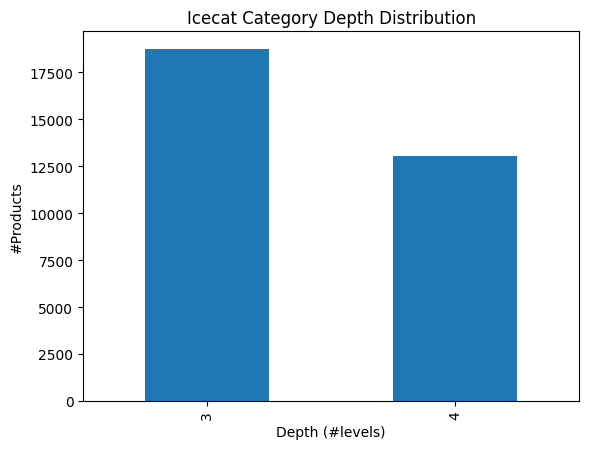

In [ ]:
depth_counts.plot(kind="bar")
plt.title("Icecat Category Depth Distribution")
plt.xlabel("Depth (#levels)")
plt.ylabel("#Products")
plt.show()


Step 8 — Standardize ALL products to 3 levels (L1, L2, L3)

In [ ]:
def standardize_3lvl(path):
    if len(path) == 0:
        return (None, None, None)
    if len(path) == 1:
        return (path[0], path[0], path[0])
    if len(path) == 2:
        return (path[0], path[1], path[1])
    # if deeper than 3 → keep root, second, and leaf
    return (path[0], path[1], path[-1])

df[["L1", "L2", "L3"]] = df["cat_list"].apply(lambda p: pd.Series(standardize_3lvl(p)))
df["cat_3lvl"] = df["L1"].fillna("") + " > " + df["L2"].fillna("") + " > " + df["L3"].fillna("")

df[["pathlist_names", "cat_3lvl"]].head(10)


,pathlist_names,cat_3lvl
0,Computers & Electronics>Batteries & Power Supp...,Computers & Electronics > Batteries & Power Su...
1,Computers & Electronics>Computers>Notebook Par...,Computers & Electronics > Computers > Notebook...
2,Computers & Electronics>Computers>Notebook Par...,Computers & Electronics > Computers > Notebook...
3,Computers & Electronics>Warranty & Support>War...,Computers & Electronics > Warranty & Support >...
4,Computers & Electronics>Computers>Notebooks,Computers & Electronics > Computers > Notebooks
5,Computers & Electronics>Computer Components>Sy...,Computers & Electronics > Computer Components ...
6,Computers & Electronics>Batteries & Power Supp...,Computers & Electronics > Batteries & Power Su...
7,Computers & Electronics>Computer Cables>USB Ca...,Computers & Electronics > Computer Cables > US...
8,Computers & Electronics>Telecom & Navigation>S...,Computers & Electronics > Telecom & Navigation...
9,Computers & Electronics>Projectors>Projector A...,Computers & Electronics > Projectors > Project...


Step 9 — Product distribution per Level-3 category (imbalance)

In [ ]:
l3_counts = df["cat_3lvl"].value_counts()
print("Unique L3 categories:", l3_counts.size)
print("Min products in a category:", l3_counts.min())
print("Max products in a category:", l3_counts.max())
l3_counts.head(10)


Unique L3 categories: 353
Min products in a category: 1
Max products in a category: 6072


,count
cat_3lvl,
Computers & Electronics > Computers > Notebook Spare Parts,6072
Computers & Electronics > Computers > Notebooks,5442
Computers & Electronics > Warranty & Support > Warranty & Support Extensions,1814
Computers & Electronics > Software > Software Licenses/Upgrades,1437
Computers & Electronics > Computers > PCs/Workstations,1425
Computers & Electronics > Printers & Scanners > Toner Cartridges,713
Computers & Electronics > Data Storage > Internal Hard Drives,531
Computers & Electronics > TVs & Monitors > TVs,530
Computers & Electronics > Data Input Devices > Keyboards,488


Step 10 — Visualize imbalance
A long-tail plot (very different from Sankey)

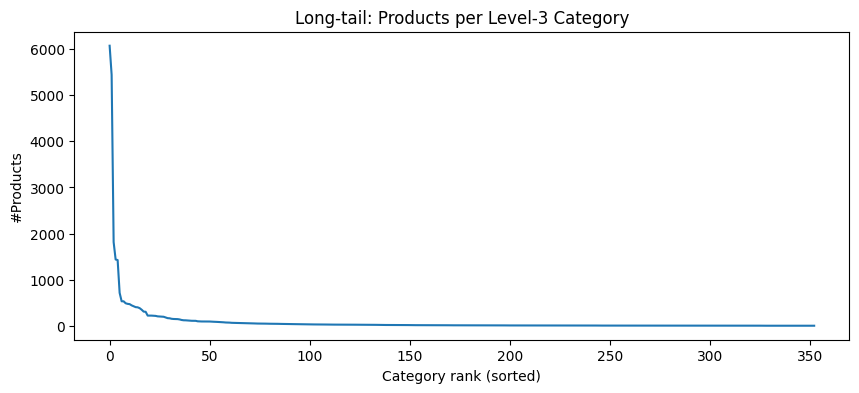

In [ ]:
sorted_counts = l3_counts.sort_values(ascending=False).values
plt.figure(figsize=(10,4))
plt.plot(np.arange(len(sorted_counts)), sorted_counts)
plt.title("Long-tail: Products per Level-3 Category")
plt.xlabel("Category rank (sorted)")
plt.ylabel("#Products")
plt.show()


IMPLEMENTATION PHASE
Step 11 — Build ML text (start without description)

In [ ]:
df["ml_text"] = (
    df["BrandInfo.BrandName"].fillna("") + " " +
    df["BrandPartCode"].fillna("")
).str.strip()

df_ml = df[df["ml_text"].str.len() >= 5].copy()
print("Rows with usable text:", len(df_ml))
df_ml[["ID", "ml_text", "cat_3lvl"]].head(5)


Rows with usable text: 31766


,ID,ml_text,cat_3lvl
0,416603,DELL U8947,Computers & Electronics > Batteries & Power Su...
1,908983,Acer 60.A46V1.009,Computers & Electronics > Computers > Notebook...
2,955069,Toshiba SIC1016062LCD0,Computers & Electronics > Computers > Notebook...
3,494327,Fujitsu FSP:GB5H00Z00GBDPH,Computers & Electronics > Warranty & Support >...
4,691783,Lenovo 20BSS0EJ06,Computers & Electronics > Computers > Notebooks


Step 12 — Filter small categories

In [ ]:
MIN_L3 = 50  # try 50, 80, 100

counts2 = df_ml["cat_3lvl"].value_counts()
valid_l3 = counts2[counts2 >= MIN_L3].index
df_work = df_ml[df_ml["cat_3lvl"].isin(valid_l3)].copy()

print("After filtering small categories:")
print("Products:", len(df_work))
print("L3 categories:", df_work["cat_3lvl"].nunique())


After filtering small categories:
Products: 28560
L3 categories: 73


Step 13 — Create SBERT embeddings

In [ ]:
encoder = SentenceTransformer("all-MiniLM-L6-v2")  # 384-dim vectors
emb = encoder.encode(
    df_work["ml_text"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)
emb = np.asarray(emb, dtype=np.float32)
print("SBERT embeddings shape:", emb.shape)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/447 [00:00<?, ?it/s]

SBERT embeddings shape: (28560, 384)


Step 14 — BIRCH clustering (main algorithm)

In [ ]:
THRESH = 0.45  # tune 0.35–0.60

birch_model = Birch(threshold=THRESH, branching_factor=50, n_clusters=None)
df_work["cluster_id"] = birch_model.fit_predict(emb)

df_work["cluster_id"].value_counts().head(10)


,count
cluster_id,
304,1606
3558,1125
3526,954
466,836
3384,414
3387,378
501,354
827,351
3391,310


Evaluation (Purity + “inside cluster” check)
Step 15 — Purity score (your target metric)

In [ ]:
def purity(df, cluster_col, true_col):
    total = 0
    correct = 0
    for _, g in df.groupby(cluster_col):
        correct += g[true_col].value_counts().iloc[0]
        total += len(g)
    return correct / total

p = purity(df_work, "cluster_id", "cat_3lvl")
print("Purity:", round(p*100, 2), "%")


Purity: 76.01 %
